# 5 · Point time series

Pull a time series out of the cube at a latitude/longitude, and plot it. This is where the
production/leadtime/event-date distinction from notebook 1 stops being bookkeeping and
starts being the thing you are looking at.

**Needs:** core dependencies, plus `matplotlib`.

> There is **no reprojection** anywhere in `meteoraster`: coordinates are geographic
> latitude/longitude throughout, and `lat`/`lon` mean exactly that. If your data is on a
> projected grid, reproject it before building the raster.

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Environment noise, nothing to do with meteoraster: xarray probes every NetCDF/GRIB
# backend it can find (cfgrib needs the ecCodes binary), and this conda env's h5py and
# HDF5 builds differ by a patch release.
warnings.filterwarnings('ignore', message='(?s).*ecCodes.*')
warnings.filterwarnings('ignore', message='(?s).*h5py is running against HDF5.*')

# Report warnings without their absolute path, so the committed output does not carry
# one machine's directory layout. The warnings themselves stay visible.
def brief_warning(message, category, filename, lineno, line=None):
    return '%s:%d: %s: %s\n' % (Path(filename).name, lineno, category.__name__, message)


warnings.formatwarning = brief_warning

# Run straight from a clone: if `meteoraster` is not installed in this environment,
# fall back to the repository root one level up.
if importlib.util.find_spec('meteoraster') is None:
    sys.path.insert(0, str(Path('..').resolve()))

from meteoraster import MeteoRaster

RESOURCES = Path('..') / 'tests' / 'resources'

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 10)

rain = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.02.02.nct', verbose=False)

LAT, LON = 50.5, 5.9          # Vesdre basin, eastern Belgium

## `get_values_from_latlon`

It takes the **nearest** grid cell — no interpolation. If several cells tie for nearest it
averages them and warns.

In [2]:
point = rain.get_values_from_latlon(lat=LAT, lon=LON)

print('asked for   : %.3f N, %.3f E' % (LAT, LON))
distance = (rain.latitudes - LAT) ** 2 + (rain.longitudes - LON) ** 2
row, col = np.unravel_index(np.argmin(distance), distance.shape)
print('nearest cell: %.3f N, %.3f E   (row %d, col %d)'
      % (rain.latitudes[row, col], rain.longitudes[row, col], row, col))
print()
print('frame       :', point.shape, '  index:', point.index.name)
print('columns     :', point.columns.names)

asked for   : 50.500 N, 5.900 E
nearest cell: 50.500 N, 6.000 E   (row 14, col 32)

frame       : (7, 129)   index: production_datetime
columns     : ['leadtime', 'ensemble_member']


meteoraster.py:830: RuntimeWarning: Mean of empty slice


(`RuntimeWarning: Mean of empty slice` is numpy, via the library, telling you it averaged
a slice that was entirely NaN — the missing production. It is a report, not a failure.)

Rows are production dates; columns are a `(leadtime, ensemble_member)` MultiIndex. This
file is deterministic, so there is one member, numbered 0.

In [3]:
point.iloc[:, :6].round(3)

leadtime,0 days 00:00:00,0 days 03:00:00,0 days 06:00:00,0 days 09:00:00,0 days 12:00:00,0 days 15:00:00
ensemble_member,0,0,0,0,0,0
production_datetime,,,,,,
2026-02-02,0.112,0.199,0.035,0.000,0.000,0.000
2026-02-03,0.000,0.000,0.000,1.676,0.043,0.514
2026-02-04,0.000,0.000,0.000,0.000,0.000,0.000
2026-02-05,0.000,0.000,0.000,0.000,0.000,0.000
2026-02-06,0.000,0.130,0.285,0.225,0.225,0.030
2026-02-07,NaN,NaN,NaN,NaN,NaN,NaN
2026-02-08,0.000,0.000,0.000,0.000,0.000,0.000


Reading across a row walks forward through one forecast. Reading down a column compares
successive forecasts at the same horizon.

The empty row is the production that is missing from this archive (notebook 1).

## One line per issue, against event time

The plot that makes the data model concrete. Each forecast issue is drawn against
`production date + leadtime`, so the curves lie where the weather is, not where the
forecast was made — and they overlap, because seven issues all cover the same fortnight.

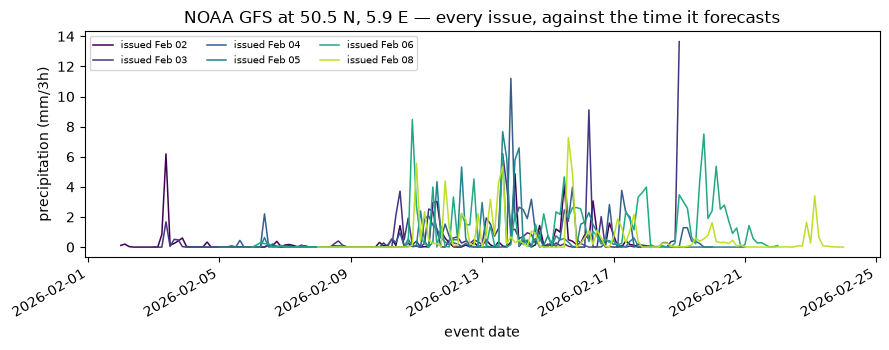

In [4]:
series = point.xs(0, level='ensemble_member', axis=1)      # drop the size-1 member level
leads = pd.to_timedelta(series.columns)

fig, ax = plt.subplots(figsize=(9, 3.6))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(series)))

for colour, (production, row) in zip(colours, series.iterrows()):
    if row.isna().all():
        continue
    ax.plot(production + leads, row.values, lw=1.1, color=colour,
            label='issued %s' % production.strftime('%b %d'))

ax.set(xlabel='event date', ylabel='precipitation (%s)' % rain.units,
       title='NOAA GFS at %.1f N, %.1f E — every issue, against the time it forecasts' % (LAT, LON))
ax.legend(fontsize=7, ncol=3)
fig.autofmt_xdate()
fig.tight_layout()

Accumulating each issue makes the disagreement between them easier to read than the
3-hourly noise does:

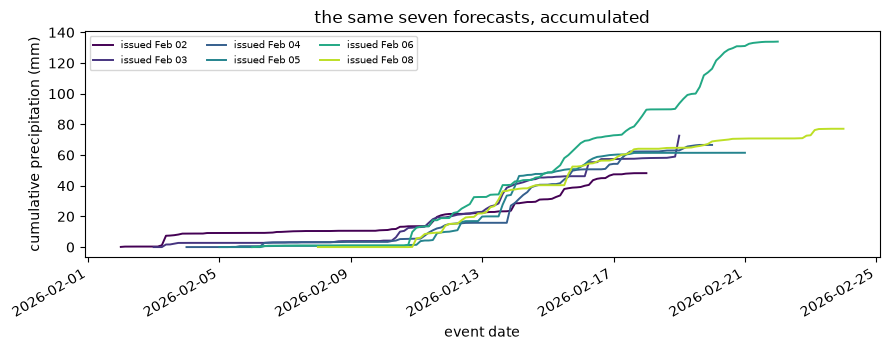

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))

for colour, (production, row) in zip(colours, series.iterrows()):
    if row.isna().all():
        continue
    ax.plot(production + leads, np.cumsum(row.values), lw=1.4, color=colour,
            label='issued %s' % production.strftime('%b %d'))

ax.set(xlabel='event date', ylabel='cumulative precipitation (mm)',
       title='the same seven forecasts, accumulated')
ax.legend(fontsize=7, ncol=3)
fig.autofmt_xdate()
fig.tight_layout()

## The other view: fixed leadtime, by event date

`get_values_from_latlon_by_event` is a static helper that re-indexes a production-date
frame onto **event** dates — each column is shifted by its own leadtime. Column *L* then
holds, at event date *t*, the value forecast *L* ahead of time.

Comparing a few columns shows how the forecast for a given moment changed as it got
closer.

frame: (177, 129)
event dates: 2026-02-02 00:00:00 -> 2026-02-24 00:00:00


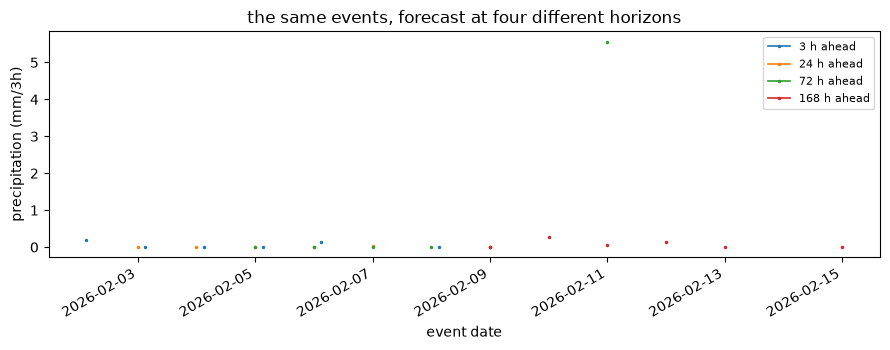

In [6]:
by_event = MeteoRaster.get_values_from_latlon_by_event(point)

print('frame:', by_event.shape)
print('event dates:', by_event.index[0], '->', by_event.index[-1])

horizons = [pd.Timedelta(hours=h) for h in (3, 24, 72, 168)]

fig, ax = plt.subplots(figsize=(9, 3.6))
for horizon in horizons:
    column = by_event.xs(horizon, level='leadtime', axis=1).iloc[:, 0]
    ax.plot(column.index, column.values, lw=1.2, marker='.', ms=3,
            label='%d h ahead' % (horizon.total_seconds() / 3600))

ax.set(xlabel='event date', ylabel='precipitation (%s)' % rain.units,
       title='the same events, forecast at four different horizons')
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()

Where the lines separate, the horizons disagree — the short-range forecast saw something
the week-ahead one did not.

## Ensembles

The same call on the ECMWF SEAS5 seasonal file returns the whole ensemble: one production,
eight members, six monthly leadtimes.

In [7]:
seas5 = MeteoRaster.load(RESOURCES / 'tethys_c3s_ecmwf51_tprate_2026.07.nct', verbose=False)
ensemble = seas5.get_values_from_latlon(lat=LAT, lon=LON)

print('frame  :', ensemble.shape, ' (1 production x 6 leadtimes x 8 members)')
print('columns:', ensemble.columns.names)
ensemble.iloc[:, :6].round(1)

frame  :

 (1, 48)  (1 production x 6 leadtimes x 8 members)
columns: ['leadtime', 'ensemble_member']


leadtime            <DateOffset: months=1>                                                                
ensemble_member                          0             1             2       3             4             5
production_datetime                                                                                       
2026-07-01                    64076.300781  16330.900391  38508.101562  7249.5  36754.199219  17344.300781

Reshaped to members × months, this is the ensemble spread — the point of a probabilistic
forecast:

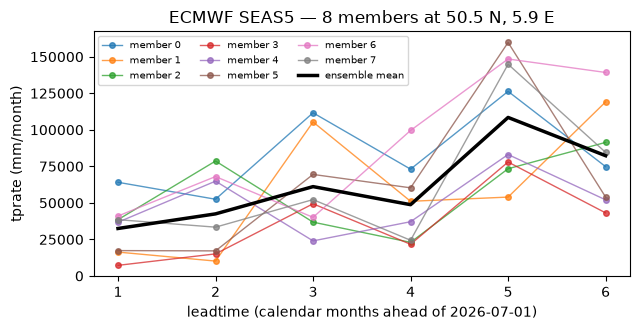

In [8]:
spread = ensemble.iloc[0].unstack('ensemble_member')
spread.index = [offset.months for offset in spread.index]
spread.index.name = 'months ahead'

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for member in spread.columns:
    ax.plot(spread.index, spread[member], marker='o', ms=4, lw=1, alpha=0.75,
            label='member %d' % member)
ax.plot(spread.index, spread.mean(axis=1), 'k-', lw=2.5, label='ensemble mean')

ax.set(xlabel='leadtime (calendar months ahead of 2026-07-01)',
       ylabel='%s (%s)' % (seas5.variable, seas5.units),
       title='ECMWF SEAS5 — 8 members at %.1f N, %.1f E' % (LAT, LON))
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()

> ⚠ **Do not read the y axis of that last figure as mm/month.** The values in this test
> fixture are about 1000× too large for the label they carry — `tprate` arrives from the
> CDS in kg m⁻² s⁻¹ (≡ mm/s) and was multiplied by 1000 anyway when the file was produced.
> It is documented in [`tests/resources/PROVENANCE.md`](../tests/resources/PROVENANCE.md)
> and the fixture is used here only for its *shape* — a real ensemble axis and real
> calendar leadtimes.

Note also that the leadtimes are `pd.DateOffset(months=n)`, not durations: "three months
ahead" is a calendar step, and the library keeps it as one.

---
**Next:** [06 · Zonal statistics from KML](06_zonal_statistics_from_kml.ipynb) — from one
pixel to whole catchments.